<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/06_neural_network_rowan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 2: a neural network as a third predictive method

Adds a neural network (`MLPRegressor`, the regression version of the network from the Session 16 and 17 labs) to the tree and k-NN, to predict a game's `average` rating from attributes known before release.

The data preparation follows the Session 17 lab (dummy columns, every input scaled to 0–1, the target scaled too and converted back to rating points before scoring) and the rows and missing values follow task 1 (notebook `05_imputation_tuning_ansel`): every game is kept and missing inputs are filled in by the median plus a "was missing" column (`SimpleImputer(strategy="median", add_indicator=True)`) inside the pipeline.

Plan: (1) the lab's architectures with default settings, and diagnosing any that fail to train; (2) sweeps of network size and of the weight penalty, training versus validation RMSE; (3) a grid search over architecture, penalty and activation; (4) a check that the result does not depend on the random starting weights; (5) one score on the test rows, next to `DummyRegressor`, linear regression and task 1's tuned tree and k-NN; (6) what drives the network.

Ground rules followed: same loading cell; `train_test_split(test_size=0.3, random_state=1)`; RMSE with MAE and R²; no post-release columns as inputs; imputer and both scalers fitted on training rows only, inside the pipeline during cross-validation; test rows scored once.

In [1]:
# --- Rowan John: task 2, a neural network (MLPRegressor) as a third predictive method ---
# [AI-assisted] Claude Code, 2026-11-10. Every code and markdown cell in this notebook was generated with Claude Code from the Session 17 lab, notebook 04 and notebook 05; reviewed and edited by Rowan John.
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning

## 1. Load, rows, split and inputs (as in notebook 05)

In [2]:
# [AI-assisted] Claude Code, 2026-11-10. Same loading cell as notebooks 02 to 05; reviewed and edited by Rowan John.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

(21631, 24)


In [3]:
# [AI-assisted] Claude Code, 2026-11-10. Task 1's rows and split: every game kept, 70/30 with random_state=1; notebook 04's input builder; reviewed and edited by Rowan John.
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
train_df, test_df = train_test_split(games, test_size=0.3, random_state=1)
y_train, y_test = train_df["average"], test_df["average"]

N_MECH, N_CAT = 20, 15
top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_MECH).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(N_CAT).index

def build_inputs(frame, numeric, mechanics, categories):
    X = frame[numeric].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        if col in X.columns:
            X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    return pd.concat([X, mech, cat], axis=1)

X_train = build_inputs(train_df, numeric_cols, top_mech, top_cat)
X_test = build_inputs(test_df, numeric_cols, top_mech, top_cat)
print("training games:", len(X_train), "| test games:", len(X_test), "| inputs:", X_train.shape[1])

training games: 15141 | test games: 6490 | inputs: 43


## 2. The network pipeline

Three steps, all fitted on training rows only:

1. **Impute** the missing inputs (task 1's choice).
2. **Scale every input to 0–1** with `MinMaxScaler`, as in the lab: a network adds up weighted inputs, so a column in big numbers (year, around 2000) would drown out the 0/1 mechanic columns.
3. **The network**, `MLPRegressor`, with the lab's `solver="lbfgs"`.

The target is scaled to 0–1 as well, as the lab does with Price, using `TransformedTargetRegressor`: it scales the training ratings before fitting and converts the predictions back to rating points automatically, so every RMSE below is in rating points, comparable with notebooks 04 and 05.

In [4]:
# [AI-assisted] Claude Code, 2026-11-10. Network pipeline factory, cross-validation helper and test scorer; reviewed and edited by Rowan John.
def make_imputer():
    return SimpleImputer(strategy="median", add_indicator=True)

def nn_pipe(**kw):
    settings = dict(hidden_layer_sizes=(5,), activation="logistic", solver="lbfgs", random_state=1)
    settings.update(kw)
    inner = Pipeline([("impute", make_imputer()), ("scale", MinMaxScaler()), ("model", MLPRegressor(**settings))])
    return TransformedTargetRegressor(regressor=inner, transformer=MinMaxScaler())

folds = KFold(n_splits=5, shuffle=True, random_state=0)
RMSE = "neg_root_mean_squared_error"

def cv_report(model, X=X_train, y=y_train):
    # 5-fold CV on the training rows: mean validation RMSE, mean training-fold RMSE, and the training steps taken in each fold.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        cv = cross_validate(model, X, y, cv=folds, scoring=RMSE, return_train_score=True, return_estimator=True, n_jobs=-1)
    steps = [est.regressor_.named_steps["model"].n_iter_ for est in cv["estimator"]] if hasattr(cv["estimator"][0], "regressor_") else [np.nan]
    return {"CV RMSE": -cv["test_score"].mean(), "train RMSE": -cv["train_score"].mean(), "steps (min-max)": f"{min(steps)}-{max(steps)}",
            "seconds per fit": cv["fit_time"].mean()}

def test_scores(y_true, pred):
    return {"test RMSE": np.sqrt(mean_squared_error(y_true, pred)), "test MAE": mean_absolute_error(y_true, pred), "test R2": r2_score(y_true, pred)}

## 3. Yardsticks: predicting the mean, and linear regression

In [5]:
# [AI-assisted] Claude Code, 2026-11-10. Cross-validated RMSE of DummyRegressor and linear regression on the same imputed, scaled inputs; reviewed and edited by Rowan John.
yardsticks = {
    "DummyRegressor (training mean)": DummyRegressor(),
    "Linear regression": Pipeline([("impute", make_imputer()), ("scale", MinMaxScaler()), ("model", LinearRegression())]),
}
cv_table = pd.DataFrame({name: cv_report(m) for name, m in yardsticks.items()}).T
cv_table[["CV RMSE", "train RMSE"]].astype(float).round(4)

,CV RMSE,train RMSE
DummyRegressor (training mean),0.9325,0.9325
Linear regression,0.7539,0.7485


## 4. First networks: the lab's four architectures with default settings

`hidden_layer_sizes=(2,)` is one hidden layer of 2 nodes; `(5, 5, 5)` is three layers of 5. Logistic (sigmoid) activation and the default stopping settings (`max_iter=200`, `tol=1e-4`), exactly as in the lab's Part 2 and 3. The "steps" column is `n_iter_`, the number of training steps the solver took in each of the five folds.

In [6]:
# [AI-assisted] Claude Code, 2026-11-10. CV RMSE and training steps for the lab's four architectures with default settings; reviewed and edited by Rowan John.
architectures = [(2,), (5,), (2, 2, 2), (5, 5, 5)]
first = pd.DataFrame({f"NN {h}, logistic, defaults": cv_report(nn_pipe(hidden_layer_sizes=h)) for h in architectures}).T
pd.concat([cv_table, first]).infer_objects().round(4)

,CV RMSE,train RMSE,steps (min-max),seconds per fit
DummyRegressor (training mean),0.9325,0.9325,nan-nan,0.0229
Linear regression,0.7539,0.7485,nan-nan,0.1229
"NN (2,), logistic, defaults",0.7614,0.7576,62-75,0.1823
"NN (5,), logistic, defaults",0.7720,0.7682,23-69,0.1828
"NN (2, 2, 2), logistic, defaults",0.9297,0.9297,1-1,0.0686
"NN (5, 5, 5), logistic, defaults",0.9320,0.9320,3-3,0.0759


**Takeaway:** with the lab's default settings no network beats linear regression (CV RMSE 0.754). The two one-layer networks stop after 23 to 75 training steps and score 0.761 and 0.772. The two three-layer networks **failed to train outright**: they stopped after 1 to 3 steps and score 0.930 and 0.932, the same as predicting the training mean (0.933). This is the failure the lab diagnoses: the first steps barely improve the fit, so the solver decides it is finished.

### The lab's fix: do not let the solver stop early

As in the lab, lower `tol` so that small improvements still count as progress, and raise `max_iter` so there is room to finish. Then the same four architectures again.

In [7]:
# [AI-assisted] Claude Code, 2026-11-10. Same four architectures with tol=1e-8 and max_iter=4000; reviewed and edited by Rowan John.
fixed = pd.DataFrame({f"NN {h}, logistic, tol 1e-8": cv_report(nn_pipe(hidden_layer_sizes=h, tol=1e-8, max_iter=4000)) for h in architectures}).T
pd.concat([cv_table, first, fixed]).infer_objects().round(4)

,CV RMSE,train RMSE,steps (min-max),seconds per fit
DummyRegressor (training mean),0.9325,0.9325,nan-nan,0.0229
Linear regression,0.7539,0.7485,nan-nan,0.1229
"NN (2,), logistic, defaults",0.7614,0.7576,62-75,0.1823
"NN (5,), logistic, defaults",0.7720,0.7682,23-69,0.1828
"NN (2, 2, 2), logistic, defaults",0.9297,0.9297,1-1,0.0686
"NN (5, 5, 5), logistic, defaults",0.9320,0.9320,3-3,0.0759
"NN (2,), logistic, tol 1e-8",0.7042,0.6964,1567-1848,3.0330
"NN (5,), logistic, tol 1e-8",0.7055,0.6793,2491-4000,8.9116
"NN (2, 2, 2), logistic, tol 1e-8",0.7003,0.6913,1537-2009,5.9012
"NN (5, 5, 5), logistic, tol 1e-8",0.6975,0.6707,1357-4000,18.2331


**Takeaway:** the fix works here exactly as in the lab. With `tol=1e-8` every network trains for 1,357 to 4,000 steps and all four now beat linear regression: (2,) 0.704, (5,) 0.705, (2, 2, 2) 0.700, (5, 5, 5) 0.698. The architecture matters far less than whether training was allowed to finish.

### How many training steps?

With `tol=1e-8` the solver stops only when it reaches `max_iter`, or when the fit genuinely stops improving. A sweep of `max_iter` for the (5,) network shows where that happens, with training-fold and validation-fold RMSE from 5-fold cross-validation.

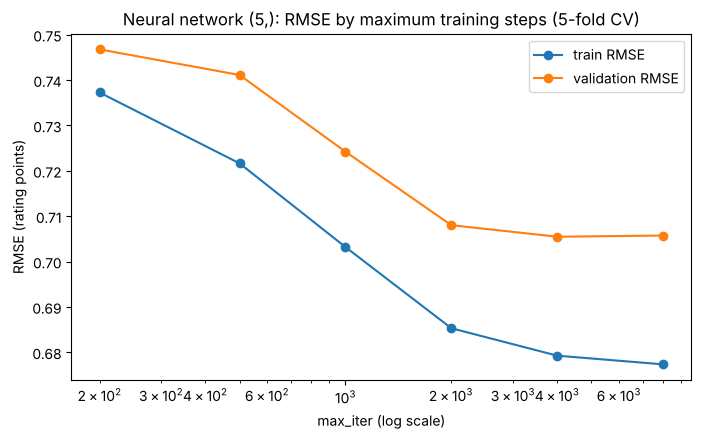

max_iter,200,500,1000,2000,4000,8000
train RMSE,0.7373,0.7216,0.7032,0.6853,0.6793,0.6773
validation RMSE,0.7468,0.7411,0.7242,0.7080,0.7055,0.7057


In [8]:
# [AI-assisted] Claude Code, 2026-11-10. Validation curve over the maximum number of training steps; reviewed and edited by Rowan John.
def sweep(model, param, values):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        train, valid = validation_curve(model, X_train, y_train, param_name=param, param_range=values, cv=folds, scoring=RMSE, n_jobs=-1)
    return pd.DataFrame({"train RMSE": -train.mean(axis=1), "validation RMSE": -valid.mean(axis=1)})

step_counts = [200, 500, 1000, 2000, 4000, 8000]
step_sweep = sweep(nn_pipe(tol=1e-8), "regressor__model__max_iter", step_counts)
step_sweep.index = pd.Index(step_counts, name="max_iter")
ax = step_sweep.plot(marker="o", figsize=(8, 4.5), logx=True)
ax.set_title("Neural network (5,): RMSE by maximum training steps (5-fold CV)")
ax.set_xlabel("max_iter (log scale)")
ax.set_ylabel("RMSE (rating points)")
save("06_nn_steps_sweep.png")
plt.show()
step_sweep.round(4).T

**Takeaway:** validation RMSE keeps falling up to about 2,000 to 4,000 steps (0.747 at 200, 0.708 at 2,000, 0.706 at 4,000) and is flat after that (0.706 at 8,000), because most folds stop on their own between 2,500 and 4,500 steps. `max_iter=4000` is used from here on: enough for training to finish, without paying for steps that change nothing.

## 5. Sweeps: how big a network, and how much penalty

### 5a. Number of nodes in one hidden layer

Training-fold and validation-fold RMSE from 5-fold cross-validation on the training rows (`validation_curve`). Bigger networks can fit the training games more closely; the question is whether the validation curve follows.

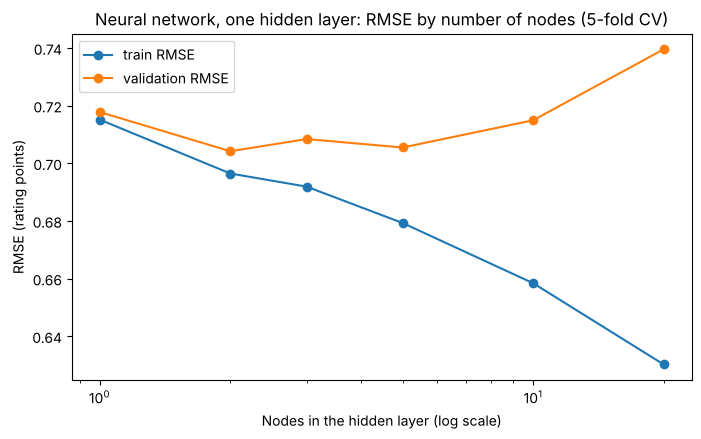

hidden nodes,1,2,3,5,10,20
train RMSE,0.7151,0.6964,0.6919,0.6793,0.6584,0.6302
validation RMSE,0.7178,0.7042,0.7084,0.7055,0.7149,0.7395


In [9]:
# [AI-assisted] Claude Code, 2026-11-10. Validation curve over the number of hidden nodes; reviewed and edited by Rowan John.
node_counts = [1, 2, 3, 5, 10, 20]
node_sweep = sweep(nn_pipe(tol=1e-8, max_iter=4000), "regressor__model__hidden_layer_sizes", [(n,) for n in node_counts])
node_sweep.index = pd.Index(node_counts, name="hidden nodes")
ax = node_sweep.plot(marker="o", figsize=(8, 4.5), logx=True)
ax.set_title("Neural network, one hidden layer: RMSE by number of nodes (5-fold CV)")
ax.set_xlabel("Nodes in the hidden layer (log scale)")
ax.set_ylabel("RMSE (rating points)")
save("06_nn_nodes_sweep.png")
plt.show()
node_sweep.round(4).T

**Takeaway:** a single hidden node already scores 0.718, and 2 to 5 nodes are best (0.704 to 0.708). Beyond that the network starts to overfit: at 20 nodes training RMSE falls to 0.630 while validation RMSE rises to 0.740, the same widening gap as the deep tree in notebook 05. With logistic activation and almost no penalty, small networks are enough.

### 5b. Weight penalty `alpha`

`alpha` is an L2 penalty on the size of the weights: larger values pull the network towards a simpler, smoother fit, the network's counterpart of a minimum leaf size in a tree. Swept here for a (5,) network.

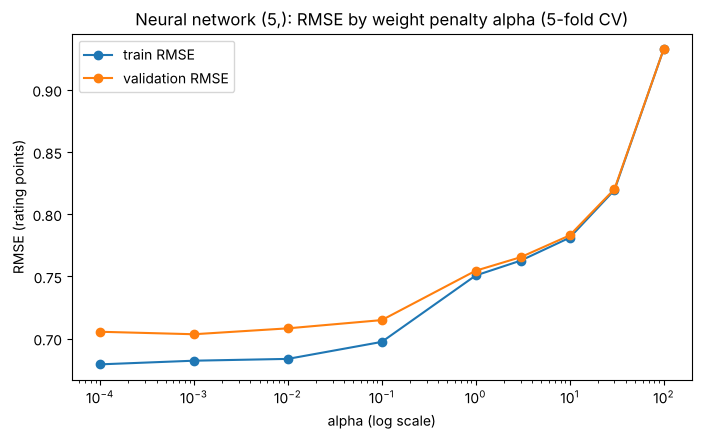

alpha,0.0001,0.0010,0.0100,0.1000,1.0000,3.0000,10.0000,30.0000,100.0000
train RMSE,0.6793,0.6822,0.6837,0.6973,0.7507,0.7626,0.7811,0.8194,0.9325
validation RMSE,0.7055,0.7035,0.7082,0.7148,0.7546,0.7654,0.7829,0.8202,0.9325


In [10]:
# [AI-assisted] Claude Code, 2026-11-10. Validation curve over the L2 penalty alpha; reviewed and edited by Rowan John.
alphas = [1e-4, 1e-3, 1e-2, 1e-1, 1, 3, 10, 30, 100]
alpha_sweep = sweep(nn_pipe(hidden_layer_sizes=(5,), tol=1e-8, max_iter=4000), "regressor__model__alpha", alphas)
alpha_sweep.index = pd.Index(alphas, name="alpha")
ax = alpha_sweep.plot(marker="o", figsize=(8, 4.5), logx=True)
ax.set_title("Neural network (5,): RMSE by weight penalty alpha (5-fold CV)")
ax.set_xlabel("alpha (log scale)")
ax.set_ylabel("RMSE (rating points)")
save("06_nn_alpha_sweep.png")
plt.show()
alpha_sweep.round(4).T

**Takeaway:** a small penalty (alpha 0.001) is marginally best (0.704). From alpha 1 upward the penalty forces the network towards a flat answer: validation RMSE rises to 0.755 at 1 and at alpha 100 every weight is pushed to zero and the network predicts the training mean (0.933). Training and validation curves stay close at every alpha, so for this small network the penalty mostly costs fit rather than curing overfitting. That changes for larger networks, which the grid search below shows.

## 6. Grid search: architecture, penalty and activation

Three hyperparameters tuned together by 5-fold cross-validation on the training rows: the architecture, `alpha`, and the activation function (logistic, the lab's sigmoid, versus ReLU).

In [11]:
# [AI-assisted] Claude Code, 2026-11-10. GridSearchCV over hidden_layer_sizes, alpha and activation; reviewed and edited by Rowan John.
nn_grid_params = {
    "regressor__model__hidden_layer_sizes": [(2,), (5,), (10,), (5, 5), (10, 10)],
    "regressor__model__alpha": [1e-4, 0.1, 1, 10],
    "regressor__model__activation": ["logistic", "relu"],
}
start = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    nn_grid = GridSearchCV(nn_pipe(tol=1e-8, max_iter=4000), nn_grid_params, cv=folds, scoring=RMSE, n_jobs=-1)
    nn_grid.fit(X_train, y_train)
print(f"{len(pd.DataFrame(nn_grid.cv_results_))} settings x 5 folds in {time.time() - start:.0f} s")
print("best settings:", {k.split("__")[-1]: v for k, v in nn_grid.best_params_.items()}, "| CV RMSE:", round(-nn_grid.best_score_, 4))
res = pd.DataFrame(nn_grid.cv_results_)
res["architecture"] = res["param_regressor__model__hidden_layer_sizes"].astype(str)
(-res.pivot_table(index="architecture", columns=["param_regressor__model__activation", "param_regressor__model__alpha"], values="mean_test_score")).round(3)

40 settings x 5 folds in 235 s
best settings: {'activation': 'relu', 'alpha': 0.1, 'hidden_layer_sizes': (10,)} | CV RMSE: 0.6923


param_regressor__model__activation logistic                            relu  \
param_regressor__model__alpha       0.0001  0.1000  1.0000  10.0000 0.0001    
architecture                                                                  
(10, 10)                              0.701   0.713   0.763   0.933   0.746   
(10,)                                 0.715   0.714   0.755   0.783   0.712   
(2,)                                  0.704   0.742   0.753   0.783   0.754   
(5, 5)                                0.694   0.717   0.762   0.933   0.719   
(5,)                                  0.705   0.715   0.755   0.783   0.709   

param_regressor__model__activation                          
param_regressor__model__alpha      0.1000  1.0000  10.0000  
architecture                                                
(10, 10)                             0.718   0.724   0.769  
(10,)                                0.692   0.722   0.758  
(2,)                                 0.754   0.753   0.763  
(5, 5)                               0.699   0.745   0.769  
(5,)                                 0.693   0.724   0.763

**Takeaway:** the best setting is **one hidden layer of 10 nodes, ReLU activation, alpha 0.1** (CV RMSE 0.692), with (5,) ReLU at the same alpha almost tied (0.693). ReLU needs the moderate penalty: at alpha 0.0001 the ReLU networks score 0.709 to 0.754, and at 0.1 the one-layer ones improve to 0.692 to 0.693. The best logistic network is (5, 5) with almost no penalty (0.694). Every architecture gets worse at alpha 1 and 10, and two-layer logistic networks at alpha 10 collapse to the mean (0.933).

## 7. Does the result depend on the random starting weights?

A network starts from random weights, so a different `random_state` can land somewhere else (the lab's Exercise 2). The tuned settings are re-run with five seeds.

In [12]:
# [AI-assisted] Claude Code, 2026-11-10. CV RMSE of the tuned network for five random seeds; reviewed and edited by Rowan John.
best_kw = {k.split("__")[-1]: v for k, v in nn_grid.best_params_.items()}
seeds = pd.DataFrame({seed: cv_report(nn_pipe(tol=1e-8, max_iter=4000, random_state=seed, **best_kw)) for seed in [1, 2, 3, 4, 5]}).T
seeds.index.name = "random_state"
print("CV RMSE across seeds: mean", round(seeds["CV RMSE"].mean(), 4), "| range", round(seeds["CV RMSE"].min(), 4), "to", round(seeds["CV RMSE"].max(), 4))
seeds.infer_objects().round(4)

CV RMSE across seeds: mean 0.6932 | range 0.6923 to 0.6944


,CV RMSE,train RMSE,steps (min-max),seconds per fit
random_state,,,,
1,0.6923,0.6638,858-1757,5.0703
2,0.6925,0.6655,934-1772,4.5715
3,0.6944,0.6615,963-1910,4.9648
4,0.6939,0.6649,1205-1588,4.9294
5,0.6928,0.6598,1402-1952,5.9065


**Takeaway:** the result does not depend on the starting weights. Across five seeds the CV RMSE ranges only from 0.692 to 0.694, and every fold trains for 858 to 1,952 steps (well under the 4,000 limit, so training finished). Seed 1, the one the grid used, is not a lucky draw.

## 8. A side attempt: the `adam` solver with early stopping

The lab used `lbfgs`. scikit-learn's default solver, `adam`, trains on small batches and can stop when a held-out 10% of the training rows stops improving (`early_stopping=True`). Tried once at the tuned architecture, to see whether it is worth switching.

In [13]:
# [AI-assisted] Claude Code, 2026-11-10. CV RMSE with adam and early stopping at the tuned architecture; reviewed and edited by Rowan John.
adam_kw = dict(best_kw, solver="adam", early_stopping=True, max_iter=500, learning_rate_init=1e-3)
adam = pd.DataFrame({"NN tuned, adam + early stopping": cv_report(nn_pipe(**adam_kw)),
                      "NN tuned, lbfgs (from the grid)": cv_report(nn_pipe(tol=1e-8, max_iter=4000, **best_kw))}).T
adam.infer_objects().round(4)

,CV RMSE,train RMSE,steps (min-max),seconds per fit
"NN tuned, adam + early stopping",0.7480,0.7399,60-96,1.1001
"NN tuned, lbfgs (from the grid)",0.6923,0.6638,858-1757,5.0281


**Takeaway:** `adam` with early stopping is five times faster (0.9 against 4.6 seconds per fit) but clearly worse: CV RMSE 0.748 against 0.692, barely better than linear regression. It stops after 60 to 96 passes, when the held-out 10% stops improving, which here is too early. The lab's `lbfgs` stays.

## 9. Score the test rows once

The tuned network, fitted on all training games, next to the yardsticks and task 1's tuned tree and k-NN refitted here with the settings notebook 05 chose, so all five are scored on the same 6,490 test games.

In [14]:
# [AI-assisted] Claude Code, 2026-11-10. Fit every model on the training rows and score once on the test rows; reviewed and edited by Rowan John.
nn_best = nn_grid.best_estimator_
final_models = {
    "DummyRegressor (training mean)": DummyRegressor(),
    "Linear regression": yardsticks["Linear regression"],
    "Regression tree (task 1 settings)": Pipeline([("impute", make_imputer()), ("model", DecisionTreeRegressor(random_state=0, max_depth=10, min_samples_leaf=30))]),
    "k-NN (task 1 settings)": Pipeline([("impute", make_imputer()), ("scale", StandardScaler()), ("model", KNeighborsRegressor(n_neighbors=30, weights="distance", p=1))]),
}
rows = {}
for name, m in final_models.items():
    m.fit(X_train, y_train)
    rows[name] = {"train RMSE": np.sqrt(mean_squared_error(y_train, m.predict(X_train))), **test_scores(y_test, m.predict(X_test))}
rows["Neural network (tuned)"] = {"train RMSE": np.sqrt(mean_squared_error(y_train, nn_best.predict(X_train))), **test_scores(y_test, nn_best.predict(X_test))}
final = pd.DataFrame(rows).T
final.round(3)

,train RMSE,test RMSE,test MAE,test R2
DummyRegressor (training mean),0.933,0.922,0.725,-0.000
Linear regression,0.749,0.744,0.574,0.348
Regression tree (task 1 settings),0.668,0.705,0.535,0.415
k-NN (task 1 settings),0.036,0.728,0.558,0.377
Neural network (tuned),0.664,0.680,0.513,0.455


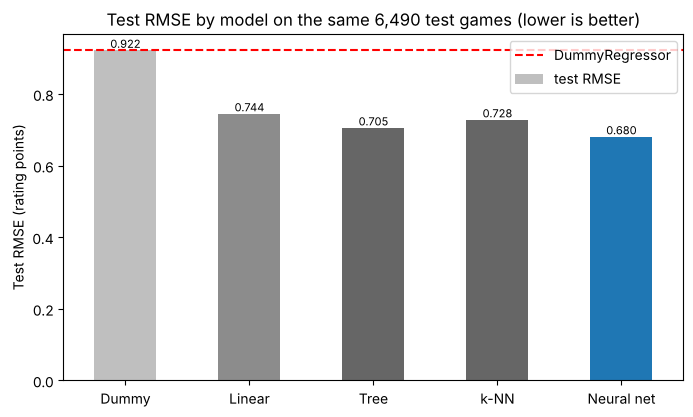

In [15]:
# [AI-assisted] Claude Code, 2026-11-10. Bar chart of test RMSE by model, with the baseline as a reference line; reviewed and edited by Rowan John.
ax = final["test RMSE"].plot(kind="bar", color=["0.75", "0.55", "0.4", "0.4", "tab:blue"], figsize=(8, 4.5), rot=0)
ax.axhline(final.loc["DummyRegressor (training mean)", "test RMSE"], color="red", linestyle="--", label="DummyRegressor")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set_xticklabels(["Dummy", "Linear", "Tree", "k-NN", "Neural net"])
ax.set_title(f"Test RMSE by model on the same {len(y_test):,} test games (lower is better)")
ax.set_ylabel("Test RMSE (rating points)")
ax.legend()
save("06_model_comparison.png")
plt.show()

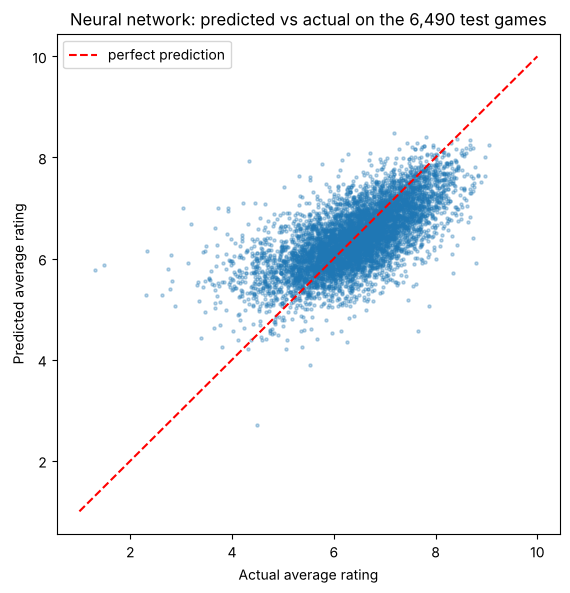

range of predictions: 2.7 to 8.48 | range of actual ratings: 1.31 to 9.05


In [16]:
# [AI-assisted] Claude Code, 2026-11-10. Predicted against actual rating for the tuned network on the test rows; reviewed and edited by Rowan John.
pred = nn_best.predict(X_test)
plt.figure(figsize=(6.5, 6.5))
plt.scatter(y_test, pred, s=5, alpha=0.3)
plt.plot([1, 10], [1, 10], color="red", linestyle="--", label="perfect prediction")
plt.xlabel("Actual average rating")
plt.ylabel("Predicted average rating")
plt.title(f"Neural network: predicted vs actual on the {len(y_test):,} test games")
plt.legend()
save("06_nn_predicted_vs_actual.png")
plt.show()
print("range of predictions:", round(pred.min(), 2), "to", round(pred.max(), 2), "| range of actual ratings:", round(y_test.min(), 2), "to", round(y_test.max(), 2))

**Takeaway: the tuned network has the lowest test error of the five models.** On the same 6,490 test games it scores RMSE **0.680**, MAE **0.513** and R² **0.455**, against 0.705 / 0.535 / 0.415 for task 1's tuned tree, 0.728 / 0.558 / 0.377 for k-NN, 0.744 / 0.574 / 0.348 for linear regression and 0.922 for the baseline. Its training RMSE (0.664) is close to the test RMSE, so it is not overfitting. On the predicted-against-actual chart the network, like the other models, pulls predictions towards the middle: they run from 2.7 to 8.5 while actual ratings run from 1.3 to 9.1, so it under-predicts the best games and over-predicts the worst. That is the pattern task 3 should look at.

## 10. What drives the network

A network has no single importance number per input the way a tree does. **Permutation importance** measures it directly: shuffle one input column across the test games, breaking its link with the rating, and see how much the RMSE rises. Ten shuffles per input.

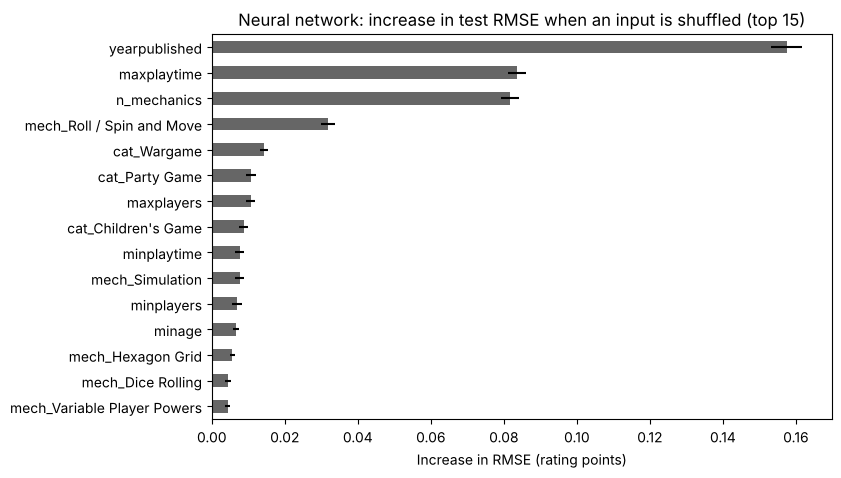

,RMSE increase,sd
yearpublished,0.1575,0.0043
maxplaytime,0.0835,0.0025
n_mechanics,0.0817,0.0025
mech_Roll / Spin and Move,0.0318,0.0019
cat_Wargame,0.0143,0.0011
cat_Party Game,0.0107,0.0014
maxplayers,0.0107,0.0013
cat_Children's Game,0.0087,0.0012
minplaytime,0.0077,0.0013
mech_Simulation,0.0076,0.0012


In [17]:
# [AI-assisted] Claude Code, 2026-11-10. Permutation importance of each input for the tuned network on the test rows; reviewed and edited by Rowan John.
perm = permutation_importance(nn_best, X_test, y_test, scoring=RMSE, n_repeats=10, random_state=0, n_jobs=-1)
perm_table = pd.DataFrame({"RMSE increase": perm.importances_mean, "sd": perm.importances_std}, index=X_test.columns).sort_values("RMSE increase", ascending=False)
top = perm_table.head(15)
ax = top["RMSE increase"].plot(kind="barh", xerr=top["sd"], color="0.4", figsize=(8, 5))
ax.invert_yaxis()
ax.set_title("Neural network: increase in test RMSE when an input is shuffled (top 15)")
ax.set_xlabel("Increase in RMSE (rating points)")
save("06_nn_permutation_importance.png")
plt.show()
top.round(4)

**Takeaway:** year of publication matters most by far: shuffling it raises test RMSE by 0.158 rating points. Maximum play time (0.084) and the number of mechanics (0.082) come next, then the Roll / Spin and Move mechanic (0.032, which lowers ratings) and the wargame category (0.014). Minimum age matters less to the network (0.007) than to notebook 04's tree. The top inputs agree with the tree's feature importance in notebooks 04 and 05, which is a useful check that the network learned the same signal rather than noise.

## 11. What did not work, and notes

- **The lab's default settings failed.** No network beat linear regression with `tol=1e-4` and `max_iter=200`, and both three-layer networks stopped after 1 to 3 steps and predicted the mean (CV RMSE 0.930 and 0.932). Lowering `tol` to `1e-8` fixed it, as in the lab.
- **More training steps helped only up to a point.** Gains stopped at about 4,000 steps; 8,000 changed nothing.
- **Bigger networks overfit.** 20 nodes in one layer gave the lowest training RMSE (0.630) but a worse validation RMSE (0.740) than 2 to 5 nodes.
- **A strong penalty flattened the network.** At alpha 10 and above, the networks moved towards predicting the mean, and at alpha 100 they predicted it exactly.
- **ReLU with no penalty was unstable.** The (10, 10) ReLU network at alpha 0.0001 scored 0.746, worse than the same network at alpha 0.1 (0.718).
- **`adam` with early stopping trained five times faster but stopped too early** (CV RMSE 0.748 against 0.692).

- Rows, split and imputer are task 1's (notebook 05): all 21,631 games, 70/30 with `random_state=1`, missing inputs filled inside the pipeline.
- Every "CV" number is 5-fold cross-validation on the training rows; every "test" number comes from scoring once, at the end.
- Figures are saved to `figures/` with the prefix `06_`.